In [ ]:
import numpy as np
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

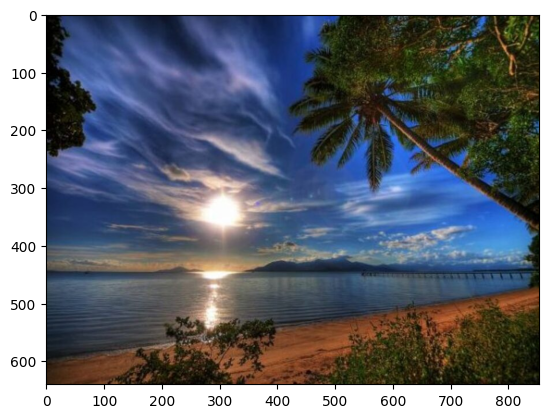

In [ ]:
img_tensor = mpimg.imread('image_for_lab2.jpeg')

red_channel = img_tensor[:, :, 0]
green_channel = img_tensor[:, :, 1]
blue_channel = img_tensor[:, :, 2]

plt.imshow(img_tensor)

In [ ]:
def power_method(matrix, iterations):
  rng = np.random.default_rng(42)
  x_k = rng.standard_normal(matrix.shape[1])
  lambda_k = 0

  for _ in range(iterations):
    dot = matrix @ x_k
    x_k_plus_1 = (dot)/np.linalg.norm(dot)

    lambda_new = ((x_k_plus_1.T @ matrix @ x_k_plus_1) / (x_k_plus_1.T @ x_k_plus_1))

    x_k = x_k_plus_1
    lambda_k = lambda_new

  return lambda_k, x_k

In [ ]:
def svd(matrix, iterations, k=0):
  if k == 0:
    r = np.linalg.matrix_rank(matrix)
  else:
    r = k

  A = matrix.copy().astype(float)

  m = A.shape[0]
  n = A.shape[1]
  sigma = np.zeros(A.shape)
  V = np.zeros((n, n))
  U = np.zeros((m, m))

  for i in range(r):
    B = A.T @ A
    lambd, v = power_method(B, iterations=iterations)
    sigma_i = np.linalg.norm(A @ v)
    u = 1/sigma_i * (A @ v)

    sigma[i, i] = sigma_i
    V[:, i] = v
    U[:, i] = u

    A = A - sigma_i * np.outer(u, v)

  return sigma, U, V

In [ ]:
sigma, U, V = svd(blue_channel, 10)
print(np.linalg.norm(blue_channel - U @ sigma @ V.T))

6.209397653507735e-11


In [ ]:
sigma, U, V = svd(red_channel, 100)
print(sigma[0, 0])

55101.43732740764


[]

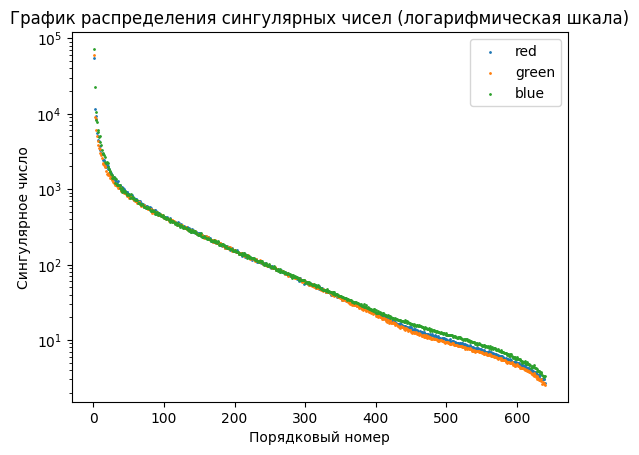

In [ ]:
r_red = np.linalg.matrix_rank(red_channel)
r_green = np.linalg.matrix_rank(green_channel)
r_blue = np.linalg.matrix_rank(blue_channel)
numbers = [i+1 for i in range(max(r_red, r_green, r_blue))]

sigma_red, _, _ = svd(red_channel, 10)
sigma_green, _, _ = svd(green_channel, 10)
sigma_blue, _, _ = svd(blue_channel, 10)

singular_values_red = [sigma_red[i, i] for i in range(r_red)]
singular_values_green = [sigma_green[i, i] for i in range(r_green)]
singular_values_blue = [sigma_blue[i, i] for i in range(r_blue)]

plt.scatter(numbers, singular_values_red, s=1, label='red')
plt.scatter(numbers, singular_values_green, s=1, label='green')
plt.scatter(numbers, singular_values_blue, s=1, label='blue')
plt.yscale('log')

plt.title(f"График распределения сингулярных чисел (логарифмическая шкала)")
plt.xlabel('Порядковый номер')
plt.ylabel('Сингулярное число')
plt.legend()
plt.savefig(f'singular_values_log_.png')
plt.plot()

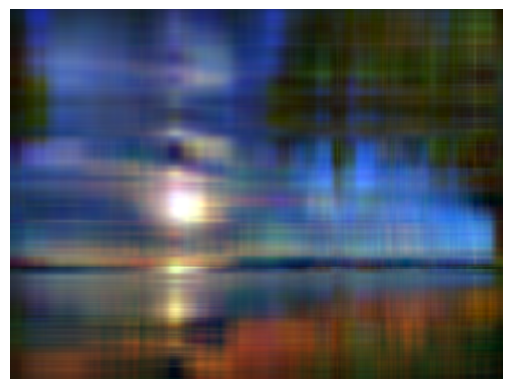

In [ ]:
k = 5
sigma_red, u_red, v_red = svd(red_channel, 10, k)
restored_red_channel = u_red @ sigma_red @ v_red.T

sigma_blue, u_blue, v_blue = svd(blue_channel, 10, k)
restored_blue_channel = u_blue @ sigma_blue @ v_blue.T

sigma_green, u_green, v_green = svd(green_channel, 10, k)
restored_green_channel = u_green @ sigma_green @ v_green.T

restored_image = np.dstack((restored_red_channel,
                            restored_green_channel,
                            restored_blue_channel))
restored_image = np.clip(restored_image, 0, 255).astype(int)

plt.imshow(restored_image)
plt.axis('off')
plt.savefig(f'restored_image_{k}.jpeg', bbox_inches='tight', pad_inches=0)
plt.show()

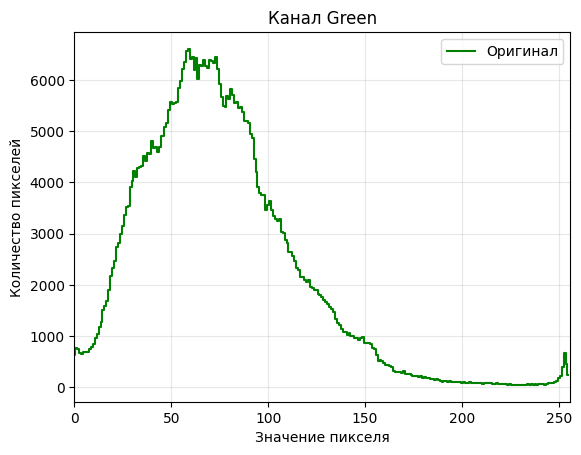

In [ ]:
sigma, u, v = svd(green_channel, 10)

hist, bin_edges = np.histogram(u @ sigma @ v.T, bins=256, range=(0, 256))

plt.step(bin_edges[:-1], hist, color='green', label='Оригинал', where='mid', linewidth=1.5)

plt.title('Канал Green')
plt.xlabel('Значение пикселя')
plt.ylabel('Количество пикселей')
plt.xlim(0, 256)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.savefig('hist_green_.png')
plt.show()

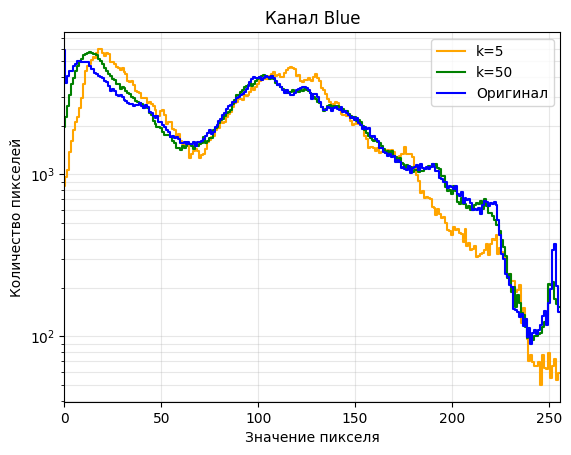

In [ ]:
sigma_5, u_5, v_5 = svd(blue_channel, 10, 5)
sigma_50, u_50, v_50 = svd(blue_channel, 10, 50)
sigma, u, v = svd(blue_channel, 10)

hist_1, bin_edges_1 = np.histogram(u_5 @ sigma_5 @ v_5.T, bins=256, range=(0, 256))
hist_2, bin_edges_2 = np.histogram(u_50 @ sigma_50 @ v_50.T, bins=256, range=(0, 256))
hist_3, bin_edges_3 = np.histogram(u @ sigma @ v.T, bins=256, range=(0, 256))

plt.step(bin_edges_1[:-1], hist_1, color='orange', label='k=5', where='mid', linewidth=1.5)
plt.step(bin_edges_2[:-1], hist_2, color='green', label='k=50', where='mid', linewidth=1.5)
plt.step(bin_edges_3[:-1], hist_3, color='blue', label='Оригинал', where='mid', linewidth=1.5)

plt.yscale('log')

plt.title('Канал Blue')
plt.xlabel('Значение пикселя')
plt.ylabel('Количество пикселей')
plt.xlim(0, 256)
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.savefig('hist_blue.png')
plt.show()

In [ ]:
img_tensor_noised = mpimg.imread('image_for_lab2_noised.jpg')

red_channel_noised = img_tensor_noised[:, :, 0]
green_channel_noised = img_tensor_noised[:, :, 1]
blue_channel_noised = img_tensor_noised[:, :, 2]

plt.imshow(img_tensor_noised)

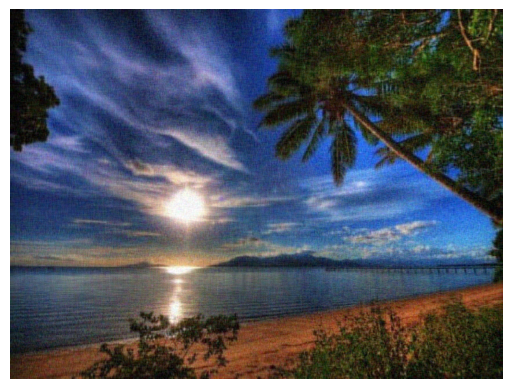

In [ ]:
sigma_red_unnoised, u_red_unnoised, v_red_unnoised = svd(red_channel_noised, 50, 100)
sigma_green_unnoised, u_green_unnoised, v_green_unnoised = svd(green_channel_noised, 50, 100)
sigma_blue_unnoised, u_blue_unnoised, v_blue_unnoised = svd(blue_channel_noised, 50, 100)

restored_red_channel_unnoised = u_red_unnoised @ sigma_red_unnoised @ v_red_unnoised.T
restored_green_channel_unnoised = u_green_unnoised @ sigma_green_unnoised @ v_green_unnoised.T
restored_blue_channel_unnoised = u_blue_unnoised @ sigma_blue_unnoised @ v_blue_unnoised.T

restored_image_unnoised = np.dstack((restored_red_channel_unnoised,
                            restored_green_channel_unnoised,
                            restored_blue_channel_unnoised))
restored_image_unnoised = np.clip(restored_image_unnoised, 0, 255).astype(int)

plt.imshow(restored_image_unnoised)
plt.axis('off')
plt.savefig(f'restored_image_unnoised.jpeg', bbox_inches='tight', pad_inches=0)
plt.show()

In [ ]:
def jacobi_rotation_method(matrix, tol, max_iter=10000):
    A = matrix.copy().astype(float)
    n = A.shape[0]
    eig_vectors = np.eye(n)
    diag_indices = np.arange(n)

    for _ in range(max_iter):
        abs_A = np.abs(A)
        abs_A[diag_indices, diag_indices] = 0.0
        flat_index = np.argmax(abs_A)
        row, col = np.unravel_index(flat_index, A.shape)

        if abs_A[row, col] < tol:
            break

        app = A[row, row]
        aqq = A[col, col]
        apq = A[row, col]

        if abs(app - aqq) < 1e-15:
            phi = np.pi / 4
        else:
            phi = 0.5 * np.arctan2(2 * apq, app - aqq)

        c = np.cos(phi)
        s = np.sin(phi)

        row_A = A[row, :].copy()
        col_A = A[col, :].copy()

        A[row, :] = c * row_A - s * col_A
        A[col, :] = s * row_A + c * col_A

        A[:, row] = A[row, :]
        A[:, col] = A[col, :]

        c2 = c * c
        s2 = s * s
        A[row, row] = c2 * app - 2 * c * s * apq + s2 * aqq
        A[col, col] = s2 * app + 2 * c * s * apq + c2 * aqq

        A[row, col] = 0.0
        A[col, row] = 0.0

        ev_row = eig_vectors[:, row].copy()
        ev_col = eig_vectors[:, col].copy()
        eig_vectors[:, row] = c * ev_row - s * ev_col
        eig_vectors[:, col] = s * ev_row + c * ev_col

    return A, eig_vectors
